package 'ACSWR' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\XPC\AppData\Local\Temp\Rtmp6Fsmj0\downloaded_packages
'data.frame':	16 obs. of  3 variables:
 $ Tip_Type   : int  1 1 1 1 2 2 2 2 3 3 ...
 $ Test_Coupon: int  1 2 3 4 1 2 3 4 1 2 ...
 $ Hardness   : num  9.3 9.4 9.6 10 9.4 9.3 9.8 9.9 9.2 9.4 ...


,Tip_Type,Test_Coupon,Hardness
,<int>,<int>,<dbl>
1,1,1,9.3
2,1,2,9.4
3,1,3,9.6
4,1,4,10.0
5,2,1,9.4
6,2,2,9.3


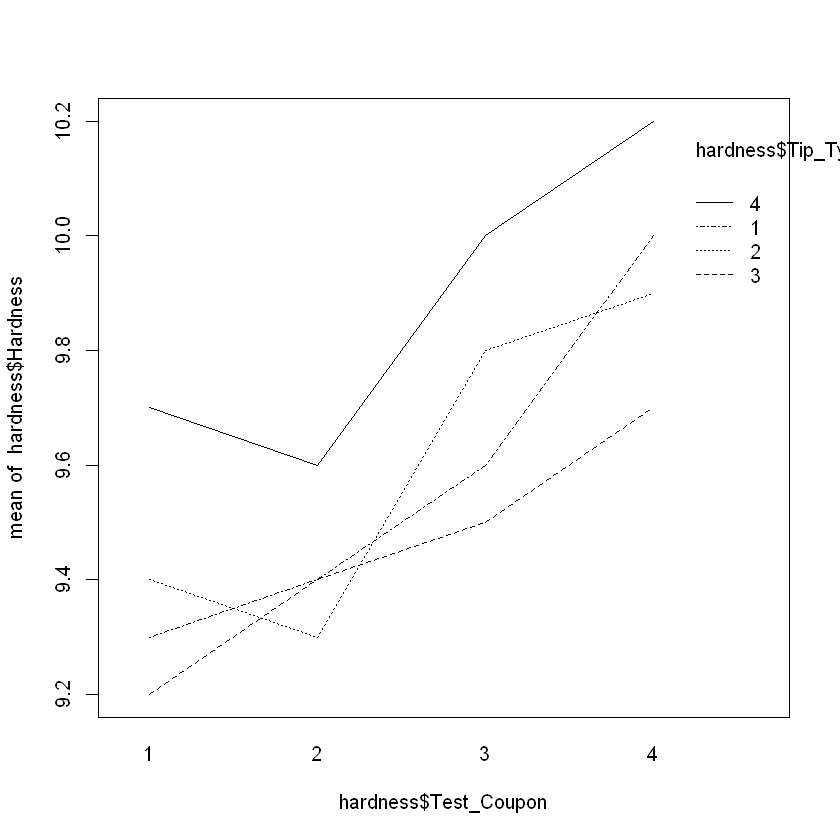

In [1]:
user_lib <- file.path(Sys.getenv("LOCALAPPDATA"), "R", "win-library", paste(R.version$major, R.version$minor, sep = "."))
if (!dir.exists(user_lib)) dir.create(user_lib, recursive = TRUE)
.libPaths(c(user_lib, .libPaths()))
if (!requireNamespace("ACSWR", quietly = TRUE)) {
  install.packages("ACSWR", lib = user_lib, repos = "https://cloud.r-project.org")
}
library(ACSWR)
# cargamos el conjunto de datos hardness
data(hardness)
# exploramos el conjunto de datos
str(hardness)
# vemos la composición de los datos de hardness
head(hardness)
# Análisis Visual mediante el Diagrama de Interación
interaction.plot(hardness$Test_Coupon,
                hardness$Tip_Type,
                hardness$Hardness)

# Parte I

## Fase 1
El grafico muestra en el eje $x$ el grupo del cupon de prueba y en el eje $y$, la media de la variable de respuesta, la dureza del cupon. Los tipos de punta se diferencian por la forma de la linea. El gráfico muestra cómo varía la dureza del metal (Hardness) según el tipo de punta (Tip_Type) y el cupón de prueba (Test_Coupon).

### a. Cada tipo de punta
- Punta 4 (linea sólida): produce en general las mayores lecturas de dureza.
- Punta 1 (linea semipunteada): presenta una tendencia creciente en la dureza. Se puede observar que es la que crece a mayor velocidad dependiendo del cupón de prueba, empieza con el menor valor y termina con el segundo mayor.
- Punta 2 (linea punteada): presenta una disminución en la dureza entre los cupones 1 y 2, pero con un crecimiento pronunciado en los cupones 2 y 3, disminuyendo la tasa de crecimiento en el cupón 4.
- Punta 3 (linea con guiones): Presenta un el crecimiento más lento en la dureza, con lecturas que se mantienen relativamente estables entre los cupones 1, 2 y 3. Presenta valores generalmente bajos.

En general, se pueden observar diferencias en la dureza según el tipo de punta. 


### b. Cada cupon
- Cupón 1: Se presenta cierta variabilidad en la dureza según el tipo de punta, con la punta 4 mostrando la mayor dureza y la punta 3 la menor.
- Cupón 2: Se puede observar una menor dispersión en la dureza entre los tipos de punta
- Cupón 3: La dureza aumenta para todas las puntas, con la punta 4 manteniendo la mayor dureza y la punta 3 la menor.
- Cupón 4: Presenta un aumento en la dureza para todas las puntas, con la punta 4 manteniendo la mayor dureza y la punta 3 la menor.

Se puede observar una tendencia general de aumento en la dureza entre los cupones 1 a 4, en orden de menor a mayor. Esto sugiere que los cupones pueden presentar diferencias en su dureza, independientemente del tipo de punta utilizado.


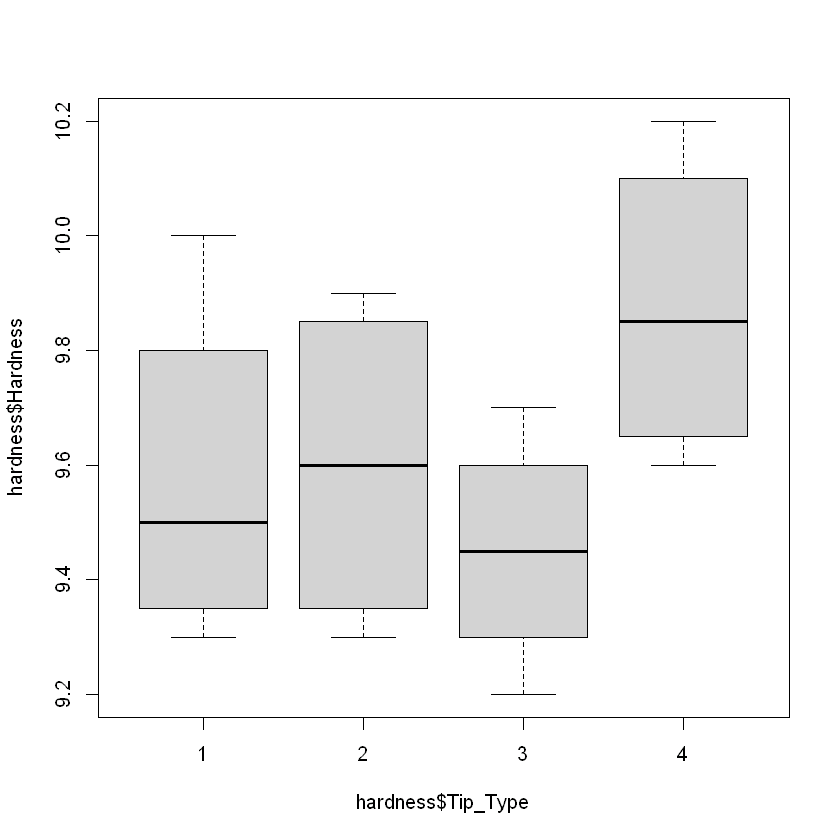

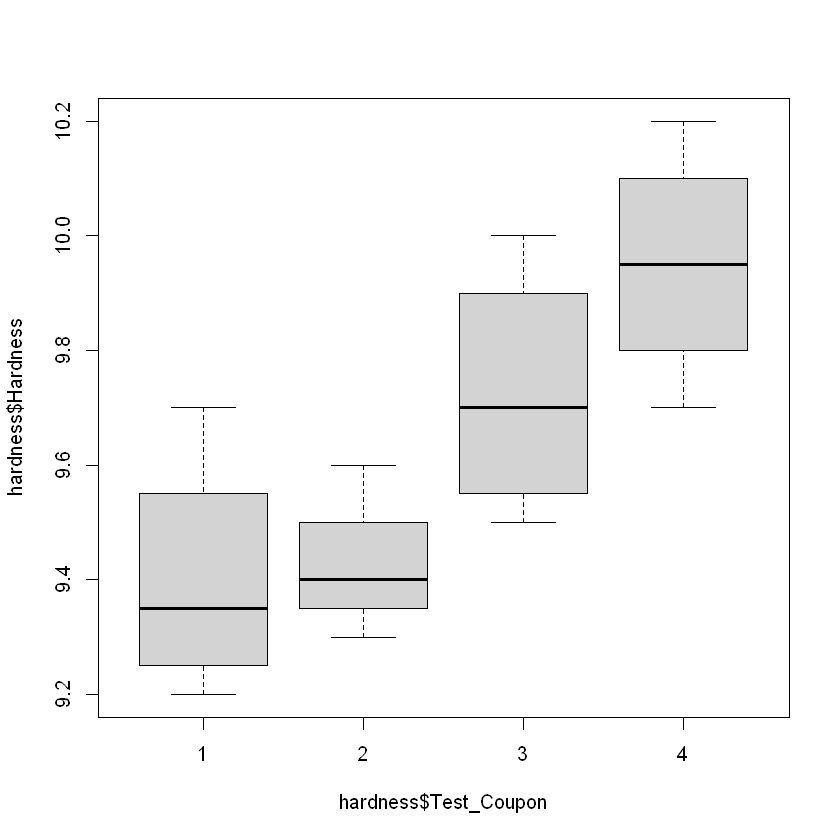

In [2]:
boxplot(hardness$Hardness ~ hardness$Tip_Type)
boxplot(hardness$Hardness ~ hardness$Test_Coupon)

## Fase 2
### 1

El boxplot muestra diferencias en las mediciones de dureza según el tipo de punta utilizado. La punta 4 presenta la mediana más alta (9.85), mientras que la punta 3 registra la más baja (9.45). En cuanto a la dispersión, la punta 2 presenta el mayor rango intercuartílico (0.50), lo que indica una mayor variabilidad en sus valores centrales. No se identificaron valores atípicos en ninguno de los cuatro grupos. Estos resultados sugieren que el tipo de punta podría influir en las mediciones de dureza, aunque será necesario realizar el ANOVA para determinar si las diferencias son estadísticamente significativas.

### 2 

El boxplot muestra una tendencia creciente en las medianas de dureza entre los cuatro cupones. El cupón 1 presenta la mediana más baja (9.35), mientras que el cupón 4 registra la más alta (9.95). Por otra parte, el cupón 2 presenta la menor dispersión de los valores centrales, con un rango intercuartílico de 0.15. No se identificaron valores atípicos. Estas diferencias sugieren que los cupones podrían contribuir a la variabilidad de las mediciones, lo que respalda la decisión de utilizarlos como bloques para controlar dicha variabilidad experimental.


In [7]:
# Fase 2:

obtenerResumenBoxplot <- function(nombreFactor) {
  factorGrupos <- hardness[[nombreFactor]]
  resultado <- boxplot(hardness$Hardness ~ factorGrupos, plot = FALSE)
  estadisticas <- resultado$stats

  data.frame(
    Grupo = resultado$names,
    Minimo = estadisticas[1, ],
    Q1 = estadisticas[2, ],
    Mediana = estadisticas[3, ],
    Q3 = estadisticas[4, ],
    Maximo = estadisticas[5, ],
    IQR = estadisticas[4, ] - estadisticas[2, ],
    Rango = estadisticas[5, ] - estadisticas[1, ],
    Valores_atipicos = tabulate(resultado$group, nbins = ncol(estadisticas)),
    row.names = NULL
  )
}

cat("Fase 2.1: Hardness según Tip_Type\n")
print(obtenerResumenBoxplot("Tip_Type"))

cat("\nFase 2.2: Hardness según Test_Coupon\n")
print(obtenerResumenBoxplot("Test_Coupon"))

Fase 2.1: Hardness según Tip_Type
  Grupo Minimo   Q1 Mediana    Q3 Maximo  IQR Rango Valores_atipicos
1     1    9.3 9.35    9.50  9.80   10.0 0.45   0.7                0
2     2    9.3 9.35    9.60  9.85    9.9 0.50   0.6                0
3     3    9.2 9.30    9.45  9.60    9.7 0.30   0.5                0
4     4    9.6 9.65    9.85 10.10   10.2 0.45   0.6                0



Fase 2.2: Hardness según Test_Coupon
  Grupo Minimo   Q1 Mediana    Q3 Maximo  IQR Rango Valores_atipicos
1     1    9.2 9.25    9.35  9.55    9.7 0.30   0.5                0
2     2    9.3 9.35    9.40  9.50    9.6 0.15   0.3                0
3     3    9.5 9.55    9.70  9.90   10.0 0.35   0.5                0
4     4    9.7 9.80    9.95 10.10   10.2 0.30   0.5                0


In [4]:
anova(aov(hardness$Hardness ~ factor(hardness$Tip_Type) +
factor(hardness$Test_Coupon)))
fit <- aov(hardness$Hardness ~ factor(hardness$Tip_Type) + factor(hardness$Test_Coupon))
TukeyHSD(fit,
which= "factor(hardness$Tip_Type)",
ordered=TRUE)

summary(aov(hardness$Hardness ~ factor(hardness$Tip_Type) +
factor(hardness$Test_Coupon)))

,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
factor(hardness$Tip_Type),3,0.385,0.128333333,14.4375,0.0008712721
factor(hardness$Test_Coupon),3,0.825,0.275000000,30.9375,0.0000452327
Residuals,9,0.080,0.008888889,NA,NA


  Tukey multiple comparisons of means
    95% family-wise confidence level
    factor levels have been ordered

Fit: aov(formula = hardness$Hardness ~ factor(hardness$Tip_Type) + factor(hardness$Test_Coupon))

$`factor(hardness$Tip_Type)`
     diff         lwr       upr     p adj
1-3 0.125 -0.08311992 0.3331199 0.3027563
2-3 0.150 -0.05811992 0.3581199 0.1815907
4-3 0.425  0.21688008 0.6331199 0.0006061
2-1 0.025 -0.18311992 0.2331199 0.9809005
4-1 0.300  0.09188008 0.5081199 0.0066583
4-2 0.275  0.06688008 0.4831199 0.0113284


                             Df Sum Sq Mean Sq F value   Pr(>F)    
factor(hardness$Tip_Type)     3  0.385 0.12833   14.44 0.000871 ***
factor(hardness$Test_Coupon)  3  0.825 0.27500   30.94 4.52e-05 ***
Residuals                     9  0.080 0.00889                     
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

## Fase 3

### 1. Interprete: ¿Qué significa la estadística F para los factores Tip_Type y Test_Coupon? ¿En general qué representa la estadística F? Para ambos casos explique la significancia de estas estadísticas.

En la estadística F se compara la variabilidad por un factor con la variabiliad aleatoria, que vendría siendo el error. Si el factor no tuviera dicho efecto, ambas serían parecidas y en ese caso F estaría próximo a 1. Un F grande indica que las diferencias entre los niveles del factor son mayores que el ruido. Por ejemplo, en Tip_Type, tenemos que F = 14.44 con un p = 0.00087, por lo que se rechaza la hipótesis nula, que sería que los cupones difieren en dureza, y de una manera aún más fuerte que el de las puntas. De este modo, se justifica haber bloqueado por cúpon, porque esa variabilidad habría quedado dentro del error experimental. Cabe recalcar que F solo permite reconocer si alguna media es distinta, más no especifica cuál lo es.

### 2. De acuerdo con los resultados de Tukey para Tip_Type, ¿qué interpretaciones podemos realizar acerca de los tipos de punta y las comparaciones de medias? Realice una prueba de Tukey para los cupones y lleve a cabo esta misma interpretación.

Con los resultados obtenidos, se puede observar que en Tip_Type, solo las comparaciones con la punta 4 son significativas, diferente a 0. Las puntas 1, 2 y 3 no se diferencian entre sí, lo que indicaría que la punta 4, al menos en las lecturas, tiene una dureza más alta que las demás sobre el mismo material. Esto significa que hay un problema con la capacidad de indicadores, por lo que habría que revisar o calibrar dicha punta, o siempre usar la misma.

Por otro lado, en Test_Coupon, los cupones 1 y 2 no difieren ya que poseen un p = 0.98, pero las demás comparaciones sí lo hacen y de forma significativa (p < 0.05). Durante la interpretación se observa que la dureza aumenta de forma escalonada, el cupón 4 es el de mayor dureza, seguido del 3 y así hasta llegar al cupón 1 y 2 que son los más blandos. Esto significa que los cupones no son de un mismo material,y que posiblemente provengan de diferentes lingotes producidos en diferentes temperaturaas, como lo menciona el enunciado. Dicho eso, fue una acertada decisión haberlos usado como bloques, ya que de esa manera la variabilidad no acabaría mezclada con los efectos de las puntas.




Call:
lm(formula = hardness$Hardness ~ factor(hardness$Tip_Type) + 
    factor(hardness$Test_Coupon))

Residuals:
     Min       1Q   Median       3Q      Max 
-0.10000 -0.05625 -0.01250  0.03125  0.15000 

Coefficients:
                              Estimate Std. Error t value Pr(>|t|)    
(Intercept)                    9.35000    0.06236 149.934  < 2e-16 ***
factor(hardness$Tip_Type)2     0.02500    0.06667   0.375 0.716345    
factor(hardness$Tip_Type)3    -0.12500    0.06667  -1.875 0.093550 .  
factor(hardness$Tip_Type)4     0.30000    0.06667   4.500 0.001489 ** 
factor(hardness$Test_Coupon)2  0.02500    0.06667   0.375 0.716345    
factor(hardness$Test_Coupon)3  0.32500    0.06667   4.875 0.000877 ***
factor(hardness$Test_Coupon)4  0.55000    0.06667   8.250 1.73e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.09428 on 9 degrees of freedom
Multiple R-squared:  0.938,	Adjusted R-squared:  0.8966 
F-statistic: 22.69 on 6 and 

  Tukey multiple comparisons of means
    95% family-wise confidence level
    factor levels have been ordered

Fit: aov(formula = hardness$Hardness ~ factor(hardness$Tip_Type) + factor(hardness$Test_Coupon))

$`factor(hardness$Test_Coupon)`
     diff         lwr       upr     p adj
2-1 0.025 -0.18311992 0.2331199 0.9809005
3-1 0.325  0.11688008 0.5331199 0.0039797
4-1 0.550  0.34188008 0.7581199 0.0000830
3-2 0.300  0.09188008 0.5081199 0.0066583
4-2 0.525  0.31688008 0.7331199 0.0001200
4-3 0.225  0.01688008 0.4331199 0.0341762


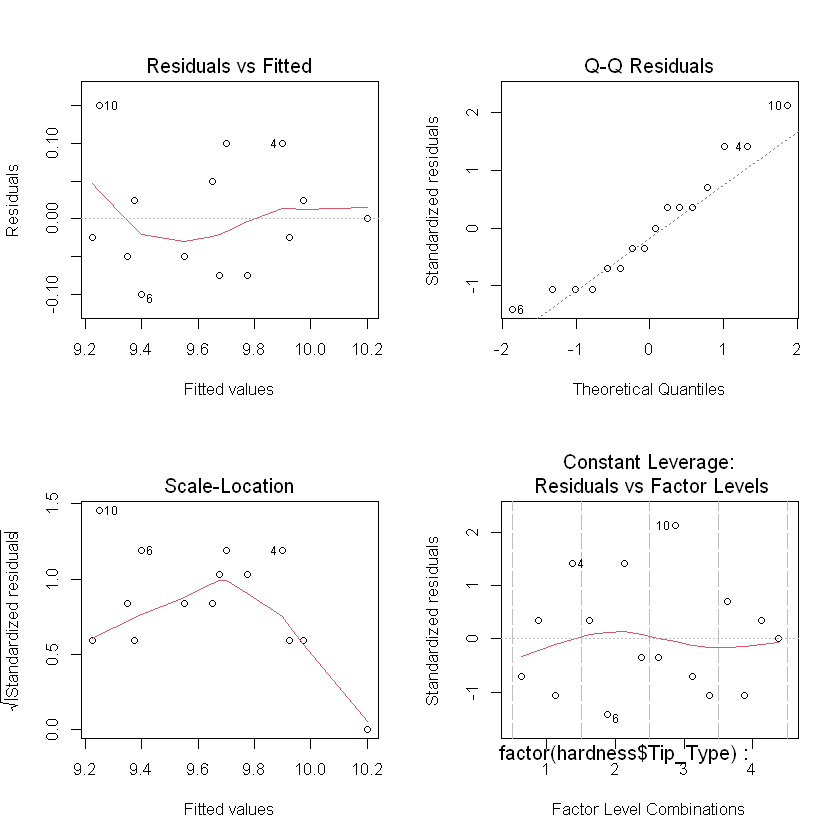

In [5]:
summary(lm(hardness$Hardness ~ factor(hardness$Tip_Type) +
factor(hardness$Test_Coupon)))

par(mfrow=c(2,2),
bg = "white",
  fg = "black",
  col.axis = "black",
  col.lab = "black",
  col.main = "black")
plot(lm(hardness$Hardness ~ factor(hardness$Tip_Type) + factor(hardness$Test_Coupon)))

TukeyHSD(fit,
which = "factor(hardness$Test_Coupon)",ordered = TRUE)

## Fase 4

### 1. En el gráfico Fitted Values vs Residuals, observamos que no existe un patrón definido, esto es esperado porque existe independencia estadística entre los residuales (un residual no depende del otro). Explique porque espera usted que esto sea algo esperado y adecuado en un conjunto de datos normalmente distribuido.
Es esperado que no haya un patrón, porque si lo hay, significaría que el modelo no está logrando explicar algo del comportamiento de los datos. Por ejemplo, si hubiese una tendencia positiva o negativa gradual en los residuos, sería preocupante porque surgiere que el modelo está ignorando algún tipo de relación importante. Es adecuado que los residuos estén dispersos, estén cerca del 0 y ser pequeños, porque en un conjunto de datos normal, se sigue la forma de la campana de Gauss, y como están centrados en 0, los residuos también se acercan al 0, teniendo valores tanto negativos como positivos. Eso sí, un conjunto de datos normal no significa necesariamente que los residuos son independientes.

### 2. En el gráfico del segundo pánel (derecha) se observa la aproximación a la distribución normal. Describa que tanto se aproxima este conjunto a la normal. ¿Puede usted decir que este conjunto esta normalmente distribuido? ¿Existe alguna prueba más que le pueda ayudar a verificar esto? 
Según el Q-Q, los residuos parecen sí tener normalidad. Se puede observar que los datos siguen la forma y están muy cerca de la línea de normalidad. Sin embargo, sólo con el gráfico no se puede asegurar nada, si no, que se debe aplicar una prueba estadística para comprobarlo. Se puede usar la de Shapiro-Wilk si son pocos datos, como en este caso. En casos con más datos, se podría usar la Liliefors.

### 3. En la esquina inferior derecha se observa la distribución estandarizada de los residuales contrastada con los niveles de factor (Puntas). Comente con base en lo que se ha discutido en clase que puede interpetar usted con respecto a la distribución de esta distribución (es homogénea o heterogénea), y si esta es adecuado o inadecuada.
Se puede observar que puntas 1 y 2 se ven bastante disperas y similares entre ellas. Punta 3 se mantiene en los valores negativos, mientras que punta 4 tiene valores positivos y parece tener variabilidad, aunque no tan amplia como la de puntas 1 y 2. Con el gráfico se puede notar que podría llegar a ser homogénea, aunque punta 3 no se vea tan dispera. La interpretación es válida, pero no adecuada como para confirmar solo con este gráfico si existe homogeneidad o no, ya que se ocupa aplicar alguna prueba como la de Levene.

# Parte II

In [6]:
library(ACSWR)
data("intensity")
intensity

Intensity,Operator,Filter,Ground
<dbl>,<fct>,<fct>,<fct>
90,1,1,low
102,1,1,medium
114,1,1,high
86,1,2,low
87,1,2,medium
93,1,2,high
96,2,1,low
106,2,1,medium
112,2,1,high


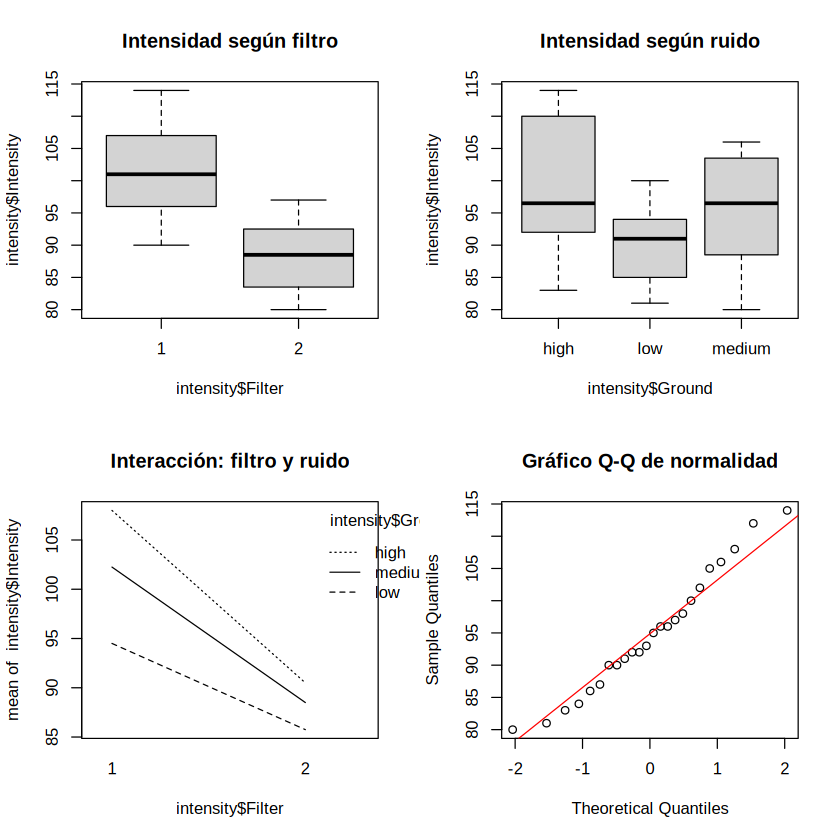

In [17]:
# Análisis Visual mediante el Diagrama de Interacción
par(mfrow = c(2, 2),
    bg = "white",
    fg = "black",
    col.axis = "black",
    col.lab = "black",
    col.main = "black")

boxplot(intensity$Intensity ~ intensity$Filter,
        main = "Intensidad según filtro")

boxplot(intensity$Intensity ~ intensity$Ground,
        main = "Intensidad según ruido")

interaction.plot(intensity$Filter,
                intensity$Ground,
                intensity$Intensity,
                main = "Interacción: filtro y ruido")

qqnorm(intensity$Intensity,
       main = "Gráfico Q-Q de normalidad")
qqline(intensity$Intensity, col = "red")

## Fase 1

El grafico de interacción muestra en el eje $x$ el grupo del filtro y en el eje $y$, la media de la variable de respuesta, la intensidad de detección. Los tipos de ruido se diferencian por la forma de la linea. El grafico muestra como la intensidad de detección varía según el tipo de ruido (Ground) y el filtro (Filter).

Se puede observar que el filtro 1 (linea sólida) presenta la mayor intensidad de detección en cada 

Se puede observar que el ruido *high* (linea punteada) presenta la mayor intensidad de detección en cada filtro, con *medium* en segundo lugar y *low* en tercer lugar, lo cual seria la tendencia esperada del efecto del ruido en la detección, entre mayor ruido, menor intensidad.

En general, la intensidad disminuye dependiendo del tipo de filtro, con el filtro 1 mostrando la mayor intensidad y el filtro 2 la menor. Esto sugiere que el tipo de filtro tiene un efecto significativo en la intensidad de detección, siendo el filtro 1 el más efectivo para mejorar la capacidad de detección en el sistema de radar. 

Esto sugiere que los ingenieros de radar deberían considerar el uso del filtro 1 para mejorar la capacidad de detección en el sistema de radar, especialmente en presencia de ruido *high*, este siendo inclusive menor que *low* usando el filtro 2.

## Fase 2

## Fase 3

## Fase 4